In [154]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

In [155]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [151]:
dataset_df = dataset.copy()

In [5]:
# dorp the meanless columns
dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

# for Age: replace the nan with the mean value.
dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

# for bill: replace the nan with zero value. 
for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
    
# for category: using the one-hot encoding.
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

In [7]:
# one-hot encoding:
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[name].unique()), dataset_df[name].unique())
    for key in dataset_df[name].unique():
        dataset_df[f'{name}_{key}'] = 0
        dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1
        
    dataset_df.drop(columns=[name], inplace=True)

In [9]:
# split the dataset
dataset_x = dataset_df.drop(columns=['Transported'])
dataset_y = dataset_df['Transported']

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
    stratify=dataset_y
)

In [141]:
dataset['PassengerId'].astype

<StringDtype(storage='python', na_value=nan)>

In [242]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### logistic regression

In [243]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

In [283]:
datatype = tc.float32
x_train = tc.tensor(x_train_df.to_numpy(), dtype=datatype)
y_train = tc.tensor(y_train_df.to_numpy(), dtype=datatype).reshape([-1, 1])

x_val = tc.tensor(x_val_df.to_numpy(), dtype=datatype)
y_val = tc.tensor(y_val_df.to_numpy(), dtype=datatype).reshape([-1, 1])

In [284]:
input_dim = x_train.shape[1]
model = tc.nn.Sequential(
    tc.nn.Linear(input_dim, 72, dtype=datatype),
    tc.nn.ReLU(),
    tc.nn.Linear(72, 36, dtype=datatype),
    tc.nn.ReLU(),
    tc.nn.Linear(36, 1, dtype=datatype)
)
# model = tc.nn.Linear(input_dim, 1, dtype=tc.float64)
loss = tc.nn.BCEWithLogitsLoss()
# optimizer = tc.optim.SGD(model.parameters(), lr=lr)
optimizer = tc.optim.Adam(model.parameters(), lr=1e-3)

scheduler = tc.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.1, patience=200)

In [285]:
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

best_state_dic = None
min_val_loss = float('inf')
couter = 0
patience = 500

epoch_num = 10000
# lr_list = [1e-4, 1e-5, 1e-6, 1e-7, 1e-6, 1e-7]

for epoch in range(epoch_num):
    
#     if epoch <= 500:
#         lr = lr_list[0]
#     elif epoch <= 1000 and epoch > 500:
#         lr = lr_list[1]
#     elif epoch <= 2000 and epoch > 1000:
#         lr = lr_list[2]
#     elif epoch <= 4000 and epoch > 2000:
#         lr = lr_list[3]
#     elif epoch <= 5000 and epoch > 4000:
#         lr = lr_list[4]
#     elif epoch <= 6000 and epoch > 5000:
#         lr = lr_list[5]
        
#     optimizer.param_groups[0]['lr'] = lr
        
    # clear the grad
    optimizer.zero_grad()
    
    # forward
    train_logits = model(x_train)
    # calculate loss
    train_loss = loss(train_logits, y_train)
    # backword & calculate grad
    train_loss.backward()
    # update parameter model.wight
    optimizer.step()
    
    with tc.no_grad():
        
        val_logits = model(x_val)
        val_loss = loss(val_logits, y_val)
        
        train_acc = tc.mean(((train_logits > 0).float() == y_train).float())
        val_acc = tc.mean(((val_logits > 0).float() == y_val).float())
        
    # scheduler
    scheduler.step(val_loss.item())
    lr = optimizer.param_groups[0]['lr']
    
    # early stopping process  
    if val_loss.item() < min_val_loss:
        min_val_loss = val_loss.item()
        best_state_dic = {
            k: v.detach().clone() for k, v in model.state_dict().items()
        }
        couter = 0
    else:
        couter += 1
    if couter > patience:
        print(f'early stopping at epoch {epoch}, best is {epoch - couter}, lr={lr}')
        break
        
    train_loss_list.append(train_loss.item())
    val_loss_list.append(val_loss.item())
    
    train_acc_list.append(train_acc.item())
    val_acc_list.append(val_acc.item())
    
    if epoch % 500 == 0:
        print(epoch, f'lr={lr}')
        
    
# results = (tc.sigmoid(model(x_val)) > 0).float()
# accuracy = tc.mean((results == y_val).float())
# print(accuracy)

0 lr=0.001
500 lr=0.001
1000 lr=1e-05
early stopping at epoch 1006, best is 505, lr=1e-05


Text(0.5, 1.0, 'val loss')

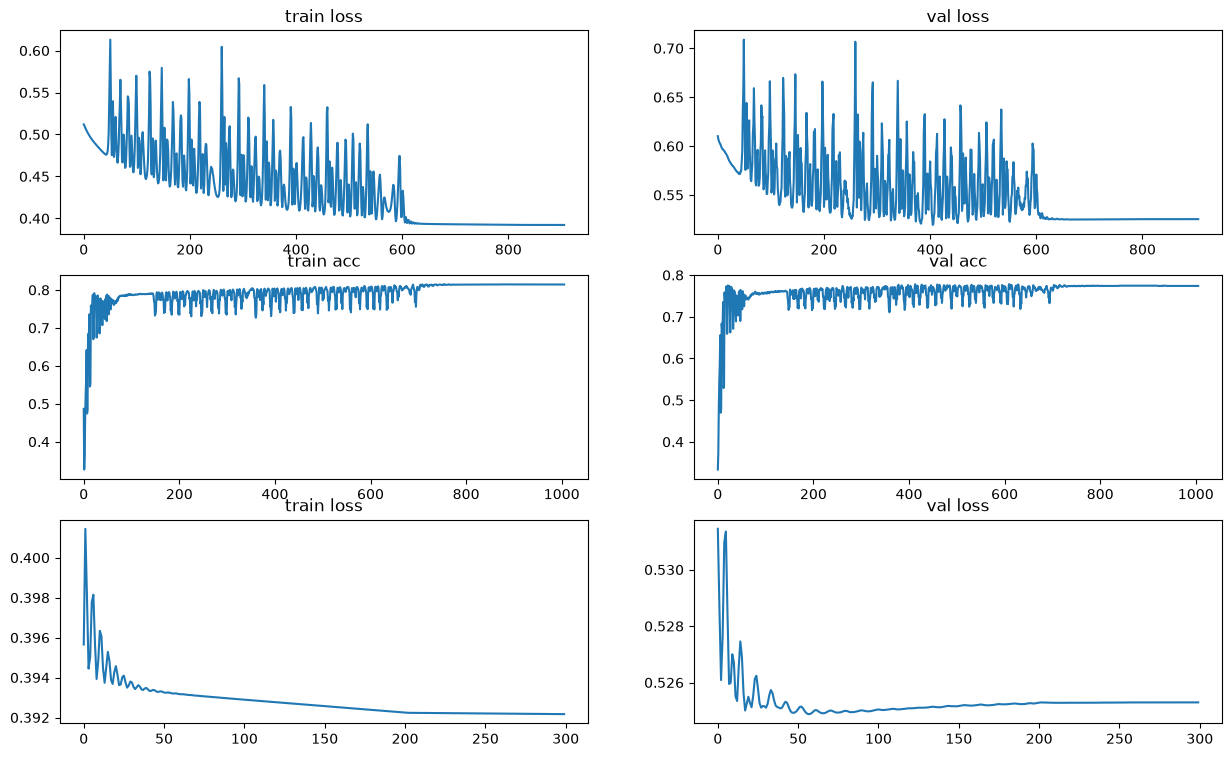

In [286]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(15, 9))
ax[0][0].plot(train_loss_list[100:])
ax[0][0].set_title('train loss')
ax[0][1].plot(val_loss_list[100:])
ax[0][1].set_title('val loss')

ax[1][0].plot(train_acc_list)
ax[1][0].set_title('train acc')
ax[1][1].plot(val_acc_list)
ax[1][1].set_title('val acc')

ax[2][0].plot(train_loss_list[-300:])
ax[2][0].set_title('train loss')
ax[2][1].plot(val_loss_list[-300:])
ax[2][1].set_title('val loss')

In [287]:
print(train_acc, val_acc)

tensor(0.8144) tensor(0.7740)


In [288]:
model.load_state_dict(best_state_dic)

<All keys matched successfully>

In [289]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(
    columns=dataset_x.columns,
    fill_value=0
)

test_x = tc.tensor(test_df.to_numpy(), dtype=datatype)

with tc.no_grad():
    test_pred = model(test_x) > 0

submit = sample.copy()
submit['Transported'] = test_pred

In [290]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [291]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [292]:
ls

data/                                   titanic_alpha_nueral_network.ipynb
submit.csv                              titanic_dataset.ipynb
titanic_alpha_logic_registration.ipynb
